# Opportunity audit for a substantial improvement

Current user-confirmed public AUC: **0.76824**. The user reports top-ten scores
displayed as 1 and top-twenty scores above 0.8, with uncertain methods/data
provenance. This motivates a competitive target, not a claim that 0.8 is
achievable from the allowed inputs. This notebook analyzes saved predictions;
no new model is fitted and no prediction is adjusted.

All nine pre-existing notebooks remain unchanged. The incremental round-four
search was stopped after seven completed screens at the user's priority change.

In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'input/train.csv').exists())
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve()
HERE=ROOT/'improvements/high_upside';ART=HERE/'artifacts'
summary=json.loads((ART/'audit_summary.json').read_text())
assert hashlib.sha256((HERE/'opportunity_audit.py').read_bytes()).hexdigest()==summary['source_sha256']
print('Python:',sys.executable)
display(summary)
display(Markdown((HERE/'OPPORTUNITY_AUDIT_PLAN.md').read_text()))

Matplotlib is building the font cache; this may take a moment.


Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python


{'reference': 'Frozen round-three three-seed development OOF recipe',
 'auc': 0.7648034854637242,
 'rows': 136961,
 'positives': 11057,
 'positive_negative_pairs': 1392120528,
 'global_pair_loss': 0.23519651453627577,
 'data_sha256': 'b8dd5a61771d8eb2821972c1b7d3f2f747cc66471f4d34153036d2d9c458ecf1',
 'split_sha256': '5edf2b0fd97c608ca1213e3870f64a719cc8c2e971f1174d5ef8085088f54121',
 'prediction_sha256': 'e2f80818c8560a72e5815952debd961b068127015a038428d4f0d15a09652484',
 'source_sha256': 'be063c48c58bf69e3312486ae329851de50b359ca5968472c5380c60d34e8738',
 'saved_capacity_diagnostic': {'model': 'improvements/round3/models/r3_cat_signed_s0_fold0.cbm',
  'own_training_sample_rows': 20000,
  'heldout_rows': 34241,
  'own_training_sample_auc': 0.81409251455652,
  'heldout_auc': 0.7651793349951106,
  'caution': 'One saved model and a sampled training subset. In-sample performance is optimistic, not validation; this cannot identify the attainable AUC ceiling.'},
 'no_models_fitted': True,
 

# Opportunity audit, before new model fitting

Reference: the frozen three-seed round-three development OOF predictions, aligned
to the unchanged development rows. The same labels have been explored before;
these are descriptive hypothesis-generation results, not independent validation.
No model fitting, learned combiner or prediction adjustment occurs in this audit.

Questions:

1. Which sufficiently large supplied-data groups account for lost positive-negative
   pair orderings? Decompose `1 - AUC` into disjoint positive-group / negative-group
   cells for external-score absence, contract, income, education and age groups.
   Sum cells back to the exact global pair loss. This avoids selecting a small
   group merely because its within-group AUC looks poor.
2. Is the error mainly within a group or between groups? Report both and the
   share of total loss. Any theoretical removable pair loss is only an optimistic
   descriptive bound; it is not an attainable prediction rule or a model forecast.
3. Do group means exhibit substantial calibration residuals, and are scores
   missing in the high-contribution groups? Sparse groups are flagged. This can
   motivate a learned representation or segment model, never hand-labeling.
4. Is obvious missing capacity a plausible explanation? On a saved CatBoost model,
   compare a deterministic sample of its own training rows with its cached held-out
   rows. This single-model in-sample diagnostic is not a performance estimate and
   cannot establish a statistical ceiling.

Output: exact evidence tables, code/data/prediction hashes, a new notebook and
shortlist of hypotheses with measured motivation. No additional data, external
labels, recovered identities, pretrained weights or changes to older notebooks.

Leaderboard feedback is recorded separately as user-reported and unverified with
respect to methods/rule compliance: top ten displayed 1; top twenty above 0.8.


## Where ranking errors occur

AUC is the fraction of positive-negative pairs ordered correctly, with half
credit for ties. Each matrix cell below contributes a fraction of **all**
positive-negative pairs to `1 - AUC`. Rows identify the positive applicant's
group; columns identify the negative applicant's group. Cells sum exactly to
the reference's global loss. Diagonal cells describe errors within groups.
Off-diagonal cells describe cross-group errors.

These are error attributions, not achievable improvements. Correcting every
selected pair independently may not correspond to any consistent score order.

In [2]:
cells=pd.read_csv(ART/'pair_loss_cells.csv',dtype={'positive_group':str,'negative_group':str})
slices=pd.read_csv(ART/'group_slices.csv',dtype={'value':str})
components=pd.read_csv(ART/'within_between_loss.csv')
for name,frame in cells.groupby('group'):
    assert abs(frame.global_auc_loss.sum()-summary['global_pair_loss'])<1e-12,name
display(components)
display(slices[slices.group=='EXT_missing_count'])
display(slices[slices.group=='NAME_CONTRACT_TYPE'])

,group,within_auc_loss,between_auc_loss,within_share_of_loss,groups
0,NAME_CONTRACT_TYPE,0.200518,0.034679,0.852554,2
1,NAME_INCOME_TYPE,0.092689,0.142507,0.394092,8
2,NAME_EDUCATION_TYPE,0.143582,0.091614,0.610478,5
3,CODE_GENDER,0.125376,0.109820,0.533071,3
4,EXT_missing_count,0.096549,0.138648,0.410503,4
5,EXT_missing_pattern,0.075247,0.159949,0.319934,8
6,age_band,0.052941,0.182256,0.225091,5


,group,value,rows,positives,negatives,positive_rate,mean_prediction,calibration_residual,auc,within_auc_loss,positive_centered_auc_loss,negative_centered_auc_loss,loss_involving_group,positive_share_of_total_loss,sparse
18,EXT_missing_count,0,28971,2050,26921,0.070760,0.069771,0.000989,0.775382,8.904566e-03,0.048427,0.042950,0.082473,0.205902,False
19,EXT_missing_count,1,77134,6210,70924,0.080509,0.079533,0.000976,0.768369,7.328309e-02,0.132332,0.130244,0.189293,0.562643,False
20,EXT_missing_count,2,30767,2791,27976,0.090714,0.090555,0.000159,0.743954,1.436104e-02,0.054310,0.061788,0.101737,0.230912,False
21,EXT_missing_count,3,89,6,83,0.067416,0.095289,-0.027873,0.640562,1.285808e-07,0.000128,0.000214,0.000342,0.000543,True


,group,value,rows,positives,negatives,positive_rate,mean_prediction,calibration_residual,auc,within_auc_loss,positive_centered_auc_loss,negative_centered_auc_loss,loss_involving_group,positive_share_of_total_loss,sparse
0,NAME_CONTRACT_TYPE,Cash loans,124000,10337,113663,0.083363,0.082307,0.001055,0.764245,0.198975,0.214362,0.218266,0.233654,0.911417,False
1,NAME_CONTRACT_TYPE,Revolving loans,12961,720,12241,0.055551,0.057441,-0.001890,0.756307,0.001543,0.020834,0.016930,0.036222,0.088583,False


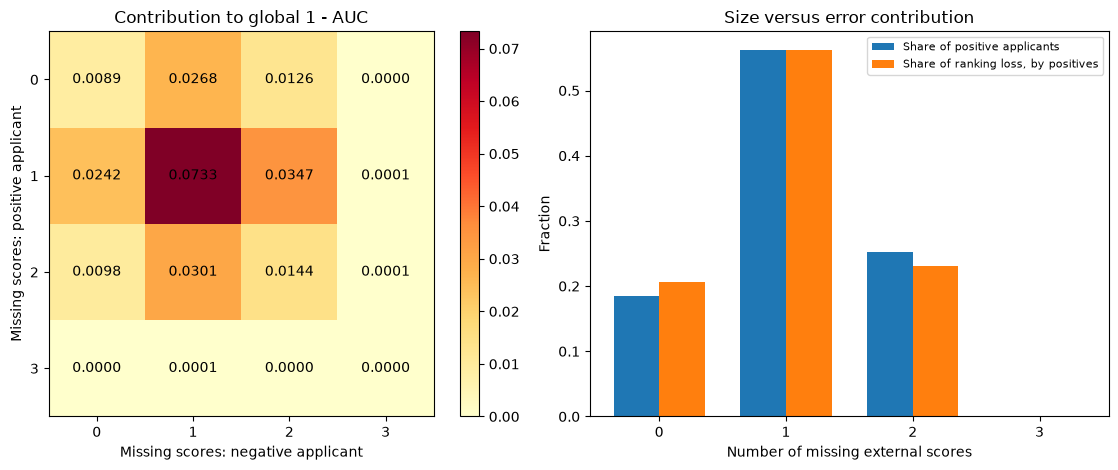

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
group='EXT_missing_count'
matrix=cells[cells.group==group].pivot(index='positive_group',columns='negative_group',values='global_auc_loss')
im=axes[0].imshow(matrix.to_numpy(),cmap='YlOrRd',vmin=0)
for i in range(len(matrix)):
    for j in range(len(matrix.columns)):
        axes[0].text(j,i,f'{matrix.iloc[i,j]:.4f}',ha='center',va='center',fontsize=10)
axes[0].set(xticks=range(len(matrix.columns)),xticklabels=matrix.columns,yticks=range(len(matrix)),yticklabels=matrix.index,
    xlabel='Missing scores: negative applicant',ylabel='Missing scores: positive applicant',title='Contribution to global 1 - AUC')
fig.colorbar(im,ax=axes[0],fraction=.046)
frame=slices[slices.group==group].sort_values('value');xx=np.arange(len(frame))
axes[1].bar(xx-.18,frame.positives/frame.positives.sum(),.36,label='Share of positive applicants')
axes[1].bar(xx+.18,frame.positive_share_of_total_loss,.36,label='Share of ranking loss, by positives')
axes[1].set(xticks=xx,xticklabels=frame.value,xlabel='Number of missing external scores',ylabel='Fraction',title='Size versus error contribution')
axes[1].legend(fontsize=8);fig.tight_layout();fig.savefig(ART/'external_score_pair_loss.png',dpi=140);plt.show()

## Interpretation without a subgroup selection trap

The two-missing-score group has lower within-group AUC, but its share of
positive-centered global ranking loss is below its share of positive cases.
Its weaker within-group AUC alone does not establish that a specialist is the
best use of compute. Most cash-loan errors occur within a large population;
this is not evidence of a single small broken segment. Large groups' mean
calibration residuals are small. A global calibration adjustment is unlikely
to explain a large ranking jump.

In [4]:
display(slices[(~slices.sparse)&(slices.group.isin(['NAME_INCOME_TYPE','NAME_EDUCATION_TYPE','age_band']))])
display(pd.Series(summary['saved_capacity_diagnostic']))

AttributeError: Can only use the '.sparse' accessor with Sparse data.

## Capacity and generalization

One saved CatBoost model has about 0.814 AUC on a deterministic sample of its
own training rows and 0.765 on its held-out rows. The in-sample number is
optimistic and is not a submission-quality estimate. This illustrates a
generalization gap, not the dataset's maximum attainable AUC. It gives little
justification for merely increasing depth without a better representation,
inductive bias or regularization strategy.

## Next hypotheses

Prioritize a scratch-trained TabM model with numerical embeddings and explicit
missingness; compare raw and the successful engineered representations. Test
selected fold-safe learned borrower/profile interactions alongside the same
reference tree learner, with a small declared pilot budget. Missing-score
reconstruction must first show out-of-fold auxiliary predictive quality and
downstream benefit; observed-score masking may not represent true missingness.
Specialists/retrieval and nested stacking remain conditional on measurable
signal and error complementarity. No larger seed bank is justified yet.

A substantial branch targets at least 0.002 OOF improvement before expensive
expansion. This is a compute-allocation target, not a promised score. All
confirmation remains on previously explored labels and must be labeled so.

In [ ]:
protected=json.loads((ROOT/'improvements/round4/reference/preserved_hashes.json').read_text());checked=0
for name,want in protected.items():
    path=ROOT/name
    if path.exists():
        assert hashlib.sha256(path.read_bytes()).hexdigest()==want,name
        checked+=1
print('Unchanged protected files present:',checked)
display(Markdown((ROOT/'HIGH_UPSIDE_PLAN.md').read_text()))

In [ ]:
RUN_AUDIT=False
if RUN_AUDIT:
    sys.path.insert(0,str(HERE))
    import opportunity_audit
    opportunity_audit.run()